# Garment Production Intelligence

## 03 — Operational Productivity Analysis

### Objective

Investigate relationships between garment production
performance and operational factors.

### Key Business Questions

1. Is overtime associated with productivity?
2. Does idle time relate to lower productivity?
3. How does workforce size relate to productivity?
4. Does SMV influence production performance?
5. Are style changes associated with productivity?
6. How do incentives relate to productivity?

### Dataset

Cleaned Garment Worker Productivity Dataset.

Source: UCI Machine Learning Repository.

In [19]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Identify project directory
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

# Locate the cleaned dataset
file_path = (
    project_dir
    / "data"
    / "processed"
    / "garments_productivity_cleaned.csv"
)

# Load dataset
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Total records:", df.shape[0])
print("Total columns:", df.shape[1])

df.head()


Dataset loaded successfully!
Total records: 1197
Total columns: 15


,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,2015-01-01,Quarter1,sewing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,2015-01-01,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,2015-01-01,Quarter1,sewing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,2015-01-01,Quarter1,sewing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,2015-01-01,Quarter1,sewing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382


In [20]:

# Select operational productivity variables

operational_columns = [
    "department",
    "team",
    "actual_productivity",
    "targeted_productivity",
    "over_time",
    "idle_time",
    "idle_men",
    "no_of_workers",
    "smv",
    "no_of_style_change",
    "incentive",
    "wip"
]

operational_df = df[operational_columns].copy()

print("Operational dataset shape:", operational_df.shape)

operational_df.head()


Operational dataset shape: (1197, 12)


,department,team,actual_productivity,targeted_productivity,over_time,idle_time,idle_men,no_of_workers,smv,no_of_style_change,incentive,wip
0,sewing,8,0.940725,0.80,7080,0.0,0,59.0,26.16,0,98,1108.0
1,finishing,1,0.886500,0.75,960,0.0,0,8.0,3.94,0,0,NaN
2,sewing,11,0.800570,0.80,3660,0.0,0,30.5,11.41,0,50,968.0
3,sewing,12,0.800570,0.80,3660,0.0,0,30.5,11.41,0,50,968.0
4,sewing,6,0.800382,0.80,1920,0.0,0,56.0,25.90,0,50,1170.0


In [21]:

# Descriptive statistics for operational variables

numeric_columns = [
    "over_time",
    "idle_time",
    "idle_men",
    "no_of_workers",
    "smv",
    "no_of_style_change",
    "incentive",
    "wip",
    "actual_productivity"
]

operational_summary = operational_df[
    numeric_columns
].describe().T

operational_summary.round(2)


,count,mean,std,min,25%,50%,75%,max
over_time,1197.0,4567.46,3348.82,0.00,1440.00,3960.00,6960.00,25920.00
idle_time,1197.0,0.73,12.71,0.00,0.00,0.00,0.00,300.00
idle_men,1197.0,0.37,3.27,0.00,0.00,0.00,0.00,45.00
no_of_workers,1197.0,34.61,22.20,2.00,9.00,34.00,57.00,89.00
smv,1197.0,15.06,10.94,2.90,3.94,15.26,24.26,54.56
no_of_style_change,1197.0,0.15,0.43,0.00,0.00,0.00,0.00,2.00
incentive,1197.0,38.21,160.18,0.00,0.00,0.00,50.00,3600.00
wip,691.0,1190.47,1837.46,7.00,774.50,1039.00,1252.50,23122.00
actual_productivity,1197.0,0.74,0.17,0.23,0.65,0.77,0.85,1.12


## Overtime vs Actual Productivity

### Business Question
Is overtime associated with higher or lower
actual productivity in garment manufacturing?

### Analysis Methods
- Pearson correlation
- Scatter plot
- Department comparison

### Important Note
Correlation does not prove causation.

In [22]:

# Calculate Pearson correlation between overtime and productivity

overtime_correlation = operational_df[
    "over_time"
].corr(
    operational_df["actual_productivity"],
    method="pearson"
)

print("Overtime vs Actual Productivity")
print("-" * 40)

print(
    f"Pearson Correlation: "
    f"{overtime_correlation:.4f}"
)


Overtime vs Actual Productivity
----------------------------------------
Pearson Correlation: -0.0542


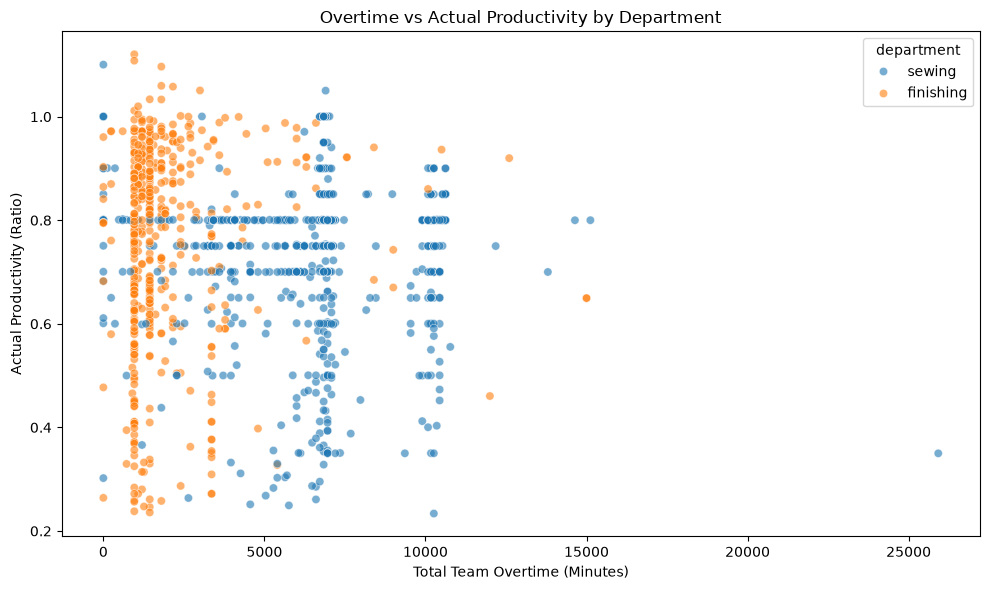

In [23]:

# Visualize overtime and actual productivity

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=operational_df,
    x="over_time",
    y="actual_productivity",
    hue="department",
    alpha=0.6
)

plt.title(
    "Overtime vs Actual Productivity by Department"
)

plt.xlabel("Total Team Overtime (Minutes)")
plt.ylabel("Actual Productivity (Ratio)")

plt.tight_layout()
plt.show()


In [24]:

# Calculate overtime-productivity correlation by department

for department, group in operational_df.groupby("department"):

    correlation = group["over_time"].corr(
        group["actual_productivity"]
    )

    print(
        f"{department.title()}: "
        f"Correlation = {correlation:.4f}"
    )


Finishing: Correlation = 0.0496
Sewing: Correlation = -0.0169


## Idle Time vs Actual Productivity

### Business Question
Is production interruption time associated with
lower actual productivity?

### Objectives
- Calculate idle time correlations.
- Identify how often interruptions occur.
- Compare productivity with and without interruptions.
- Investigate differences between departments.

### Important Note
Correlation does not establish causation.

In [25]:

# Investigate production interruption frequency

total_records = len(operational_df)

idle_records = (operational_df["idle_time"] > 0).sum()

no_idle_records = (
    operational_df["idle_time"] == 0
).sum()

idle_percentage = idle_records / total_records * 100

print("IDLE TIME SUMMARY")
print("-" * 40)

print("Total records:", total_records)
print("Records with idle time:", idle_records)
print("Records without idle time:", no_idle_records)
print(f"Records with interruptions: {idle_percentage:.2f}%")


IDLE TIME SUMMARY
----------------------------------------
Total records: 1197
Records with idle time: 18
Records without idle time: 1179
Records with interruptions: 1.50%


In [26]:

# Calculate idle time vs productivity correlation

idle_corr = operational_df["idle_time"].corr(
    operational_df["actual_productivity"],
    method="pearson"
)

print("Overall Idle Time Correlation:")
print(f"Pearson r = {idle_corr:.4f}")

print("\nCorrelation by Department:")

for department, group in operational_df.groupby("department"):

    if group["idle_time"].nunique() < 2:
        print(
            f"{department.title()}: "
            "Cannot calculate - insufficient variation"
        )
    else:
        corr = group["idle_time"].corr(
            group["actual_productivity"]
        )

        print(f"{department.title()}: r = {corr:.4f}")


Overall Idle Time Correlation:
Pearson r = -0.0809

Correlation by Department:
Finishing: Cannot calculate - insufficient variation
Sewing: r = -0.1137


In [27]:

# Compare productivity for observations with interruptions

idle_comparison = operational_df.copy()

idle_comparison["idle_status"] = np.where(
    idle_comparison["idle_time"] > 0,
    "Interruption",
    "No Interruption"
)

idle_summary = idle_comparison.groupby(
    "idle_status"
).agg(
    total_records=("actual_productivity", "size"),
    avg_productivity=("actual_productivity", "mean")
)

idle_summary["avg_productivity"] *= 100

display(idle_summary.round(2))


,total_records,avg_productivity
idle_status,,
Interruption,18,49.18
No Interruption,1179,73.88


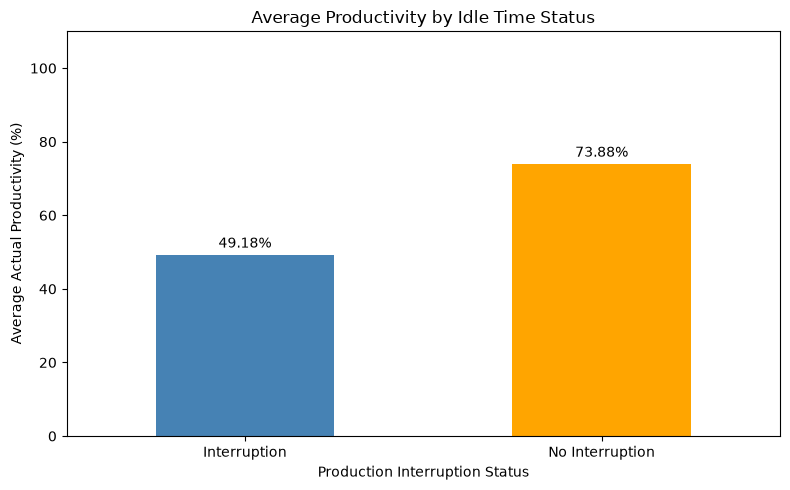

In [28]:

import matplotlib.pyplot as plt

ax = idle_summary["avg_productivity"].plot(
    kind="bar",
    figsize=(8, 5),
    color=["steelblue", "orange"]
)

plt.title("Average Productivity by Idle Time Status")
plt.xlabel("Production Interruption Status")
plt.ylabel("Average Actual Productivity (%)")
plt.xticks(rotation=0)
plt.ylim(0, 110)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()


## Idle Time Analysis by Department

### Objective
Investigate which production departments experienced
interruptions and compare their productivity.

This analysis helps determine whether the overall
productivity difference varies between departments.

In [29]:

# Investigate idle time by department

idle_department = operational_df.copy()

idle_department["has_interruption"] = (
    idle_department["idle_time"] > 0
)

department_idle_summary = idle_department.groupby(
    "department"
).agg(
    total_records=("idle_time", "size"),
    interruption_records=("has_interruption", "sum"),
    avg_idle_time=("idle_time", "mean"),
    avg_productivity=("actual_productivity", "mean")
)

department_idle_summary["interruption_rate"] = (
    department_idle_summary["interruption_records"]
    / department_idle_summary["total_records"] * 100
)

department_idle_summary["avg_productivity"] *= 100

display(department_idle_summary.round(2))


,total_records,interruption_records,avg_idle_time,avg_productivity,interruption_rate
department,,,,,
finishing,506,0,0.00,75.3,0.0
sewing,691,18,1.26,72.2,2.6


In [30]:

# Compare productivity by department and interruption status

idle_department["interruption_status"] = np.where(
    idle_department["has_interruption"],
    "Interruption",
    "No Interruption"
)

department_comparison = idle_department.groupby(
    ["department", "interruption_status"]
).agg(
    records=("actual_productivity", "size"),
    avg_productivity=("actual_productivity", "mean")
).reset_index()

department_comparison["avg_productivity"] *= 100

display(department_comparison.round(2))


,department,interruption_status,records,avg_productivity
0,finishing,No Interruption,506,75.30
1,sewing,Interruption,18,49.18
2,sewing,No Interruption,673,72.82



## Operational Analysis — Business Findings

### Finding 1: Overtime and Productivity

Pearson correlations:

- Finishing: r = 0.0496
- Sewing: r = -0.0169

Both departments showed very weak linear associations
between total team overtime and actual productivity.

Total overtime alone does not explain the differences
in productivity.

### Finding 2: Production Interruptions

The dataset contains 18 observations with recorded
production interruptions.

All 18 observations belong to the sewing department.

Average sewing productivity:

- With interruptions: 49.18%
- Without interruptions: 72.82%

Difference: 23.64 percentage points.

The interrupted group had substantially lower
average productivity.

### Business Recommendations

1. Investigate the reasons for interruptions
   in the sewing department.
2. Monitor interruption frequency and duration.
3. Compare overtime relative to team size.
4. Investigate whether garment complexity, workforce
   size, or other factors explain productivity gaps.

### Limitations

Only 18 sewing observations recorded interruptions.

These findings describe associations in historical
observational data.

They do not establish that interruptions directly
caused lower productivity.


## Workforce Size vs Actual Productivity

### Business Question
Is the number of workers in a production team
associated with actual productivity?

### Objectives
- Measure the relationship using Pearson correlation.
- Compare sewing and finishing departments.
- Visualize workforce size against productivity.
- Identify possible implications for production planning.

In [31]:

# Calculate workforce size vs productivity correlation

workforce_corr = operational_df[
    "no_of_workers"
].corr(
    operational_df["actual_productivity"],
    method="pearson"
)

print("WORKFORCE SIZE VS PRODUCTIVITY")
print("-" * 40)

print(f"Overall Pearson Correlation: {workforce_corr:.4f}")


WORKFORCE SIZE VS PRODUCTIVITY
----------------------------------------
Overall Pearson Correlation: -0.0580


In [32]:

# Workforce-productivity relationship by department

for department, group in operational_df.groupby("department"):

    correlation = group["no_of_workers"].corr(
        group["actual_productivity"]
    )

    print(
        f"{department.title()}: "
        f"Correlation = {correlation:.4f}"
    )


Finishing: Correlation = 0.2740
Sewing: Correlation = 0.0034


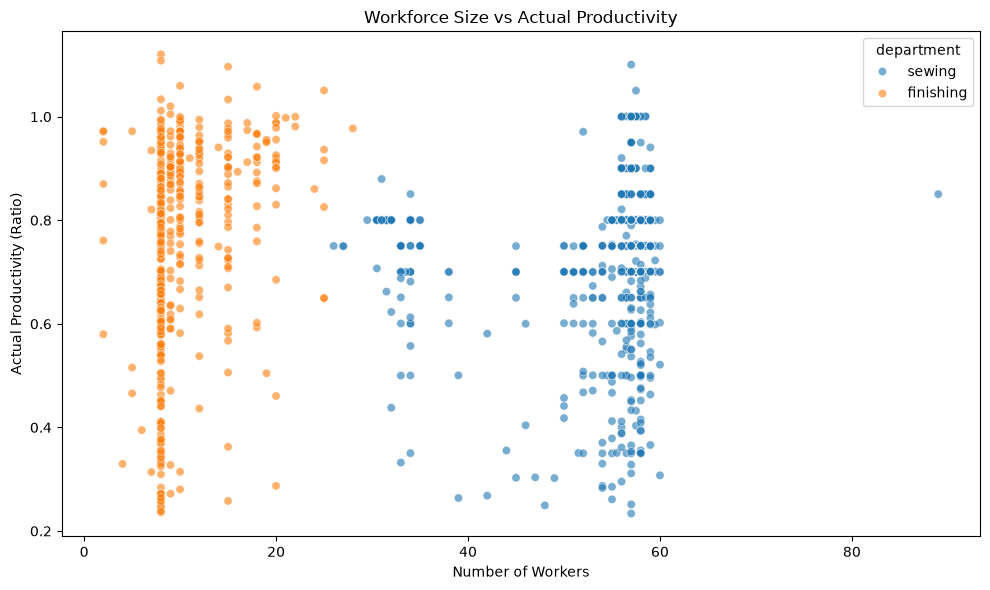

In [33]:

# Visualize workforce size vs actual productivity

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=operational_df,
    x="no_of_workers",
    y="actual_productivity",
    hue="department",
    alpha=0.6
)

plt.title("Workforce Size vs Actual Productivity")
plt.xlabel("Number of Workers")
plt.ylabel("Actual Productivity (Ratio)")

plt.tight_layout()
plt.show()


In [34]:

# Summarize workforce size by department

workforce_summary = operational_df.groupby(
    "department"
).agg(
    total_records=("no_of_workers", "size"),
    avg_workers=("no_of_workers", "mean"),
    min_workers=("no_of_workers", "min"),
    max_workers=("no_of_workers", "max"),
    avg_productivity=("actual_productivity", "mean")
)

workforce_summary["avg_productivity"] *= 100

display(workforce_summary.round(2))


,total_records,avg_workers,min_workers,max_workers,avg_productivity
department,,,,,
finishing,506,10.25,2.0,28.0,75.3
sewing,691,52.45,26.0,89.0,72.2


## Workforce Size Analysis — Final Results

### Objective
Summarize the relationship between workforce size
and actual productivity for each department.

The analysis uses Pearson correlation to measure
linear relationships.

Correlation does not establish causation.

In [35]:

# Final workforce-productivity correlation report

overall_corr = operational_df["no_of_workers"].corr(
    operational_df["actual_productivity"]
)

print("WORKFORCE SIZE VS PRODUCTIVITY")
print("-" * 45)
print(f"Overall correlation: {overall_corr:.4f}")

print("\nDepartment correlations:")

for department, group in operational_df.groupby("department"):

    correlation = group["no_of_workers"].corr(
        group["actual_productivity"]
    )

    print(f"{department.title()}: {correlation:.4f}")

print("\nAverage workers by department:")
print(
    workforce_summary["avg_workers"].round(2)
)


WORKFORCE SIZE VS PRODUCTIVITY
---------------------------------------------
Overall correlation: -0.0580

Department correlations:
Finishing: 0.2740
Sewing: 0.0034

Average workers by department:
department
finishing    10.25
sewing       52.45
Name: avg_workers, dtype: float64



## Workforce Size Analysis — Business Findings

### Correlation Results

- Overall Pearson correlation: -0.0580
- Finishing department: +0.2740
- Sewing department: +0.0034

### Department Workforce Comparison

- Average finishing workforce: 10.25 workers
- Average sewing workforce: 52.45 workers

### Key Findings

1. Overall workforce size has a very weak negative
   linear relationship with actual productivity.

2. The finishing department shows a weak positive
   correlation between workforce size and productivity.

3. The sewing department shows almost no linear
   relationship between workforce size and productivity.

4. Workforce sizes differ substantially between the
   sewing and finishing departments.

### Business Recommendations

- Analyse workforce size separately by department.
- Investigate work allocation and production complexity.
- Monitor productivity together with workforce requirements.
- Examine whether overtime per worker provides more
  meaningful insights than total team overtime.

### Limitations

These findings are based on observational data.

Correlation does not prove that increasing or decreasing
the number of workers will change productivity.

Other factors may influence the observed relationships.
